# Does wage growth predict US inflation?

**Questions**
1. Does wage growth help predict core PCE inflation once energy prices, labor-market slack and inflation expectations are accounted for?
2. Do models that use wage growth forecast core PCE inflation better *out of sample* than simple benchmarks?

**Approach.** Lead/lag (Granger) tests, a Phillips-curve regression with HAC standard errors, and an expanding-window backtest with an explicit embargo so no model sees outcomes that were not yet known. Everything here is predictive; none of it identifies causal effects.

**Data.** Monthly FRED series (see `src/fetch.py`). Requires a free API key in the `FRED_API_KEY` environment variable.

In [1]:
import os, sys
# make `src` importable whether the notebook is run from the repo root or from notebooks/
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import warnings
import matplotlib.pyplot as plt
import pandas as pd

from src import models
from src.analysis import derive
from src.fetch import build_dataset

warnings.filterwarnings("ignore", category=UserWarning)
pd.options.display.float_format = "{:.3f}".format

HORIZON = 6   # forecast core PCE inflation over the next 6 months
raw = build_dataset()
df = derive(raw)
print(df.index.min().date(), "to", df.index.max().date(), f"({len(df)} months)")
df[["core_pce", "wages", "energy_cpi", "unrate", "infl_exp"]].tail()

2007-01-01 to 2026-09-01 (237 months)


,core_pce,wages,energy_cpi,unrate,infl_exp
2026-05-01,129.796,37.490,338.639,4.300,4.800
2026-06-01,129.969,37.590,319.290,4.200,4.600
2026-07-01,130.133,37.640,314.553,4.100,4.200
2026-08-01,130.455,37.760,321.148,4.100,4.000
2026-09-01,NaN,37.810,337.834,4.200,NaN


## 1. Data checks

Missing months matter: the 2025 federal shutdown left October 2025 out of the CPI and household-survey series. Core PCE, the target, was not affected.

In [2]:
cols = ["core_pce", "wages", "energy_cpi", "unrate", "infl_exp"]
missing = df[cols].isna()
print("Months with a missing model input:")
print(missing[missing.any(axis=1)].sum(axis=0)[lambda s: s > 0])

frame = models.build_features(df, horizon=HORIZON)
print("\nUsable rows after building features:", len(frame.dropna(subset=models.FULL_FEATURES + ["target"])))
models.adf_table(frame, ["infl_1m", "wage_1m"])

Months with a missing model input:
core_pce      1
energy_cpi    1
unrate        1
infl_exp      1
dtype: int64

Usable rows after building features: 216


,n,ADF p-value,stationary at 5%
series,,,
infl_1m,235,0.211,False
wage_1m,236,0.000,True


## 2. Do wages lead inflation? (Granger tests)

Low p-values mean the first series helps predict the second beyond its own past. The reverse direction tests the "wage-price spiral" feedback. Series that fail a stationarity test are first-differenced first.

In [3]:
models.granger_table(frame, maxlag=6)

,wages -> inflation,inflation -> wages
lag (months),,
1,0.016,0.001
2,0.184,0.012
3,0.003,0.029
4,0.003,0.038
5,0.019,0.074
6,0.028,0.082


## 3. Phillips-curve regression

Future core inflation regressed on current inflation, energy prices, unemployment, expectations and wage growth. Forecast windows overlap, so residuals are autocorrelated and the standard errors are HAC (Newey-West).

In [4]:
table, summary = models.phillips_regression(frame, horizon=HORIZON)
print(summary)
table

{'n': 216, 'first month': '2008-01', 'last month': '2026-02', 'adj R2 without wages': 0.5663346487093315, 'adj R2 with wages': 0.6725248962910451, 'joint p-value, wage terms': 6.441190837017577e-06}


,coef,std err (HAC),p-value,CI low,CI high
const,-0.641,0.402,0.111,-1.429,0.147
infl_3m,0.464,0.193,0.016,0.086,0.843
infl_12m,0.109,0.199,0.584,-0.281,0.498
energy_3m,0.015,0.016,0.350,-0.016,0.046
unrate,0.072,0.043,0.094,-0.012,0.155
infl_exp,-0.081,0.188,0.665,-0.450,0.288
wage_3m,0.021,0.040,0.608,-0.058,0.100
wage_12m,0.435,0.087,0.000,0.265,0.605


In [5]:
# Is the role of wage growth stable before and after 2021?
models.regime_comparison(frame, horizon=HORIZON)

,n,wage_12m coef,wage_12m p-value,"joint p-value, wage terms"
period,,,,
before 2021,156,0.284,0.059,0.121
2021 onward,60,0.278,0.001,0.000


## 4. Out-of-sample backtest

Models are refit every month on rows whose outcomes were already observed at that time (`train_mask`). Benchmarks: trailing 12-month inflation (naive), an autoregressive ridge model, ridge with energy/slack/expectations, ridge with wage growth added, and gradient boosting. Accuracy is compared with RMSE, MAE and a Diebold-Mariano test against the naive benchmark.

In [6]:
preds = models.walk_forward(frame, horizon=HORIZON)
scores = models.score_periods(preds, HORIZON)
for label, tbl in scores.items():
    print(label)
    display(tbl)

Full sample


,RMSE,MAE,RMSE vs naive,DM p-value vs naive
model,,,,
Naive (trailing 12m inflation),1.107,0.742,NaN,NaN
Ridge: own lags,1.524,0.930,1.376,0.252
"Ridge: + energy, slack, expectations",1.511,0.953,1.365,0.226
Ridge: + wage growth,1.383,0.864,1.250,0.272
Gradient boosting: + wage growth,1.292,0.820,1.167,0.317


2023 onward


,RMSE,MAE,RMSE vs naive,DM p-value vs naive
model,,,,
Naive (trailing 12m inflation),0.908,0.621,NaN,NaN
Ridge: own lags,0.736,0.582,0.810,0.445
"Ridge: + energy, slack, expectations",0.894,0.726,0.985,0.935
Ridge: + wage growth,0.728,0.563,0.802,0.428
Gradient boosting: + wage growth,0.969,0.748,1.068,0.612


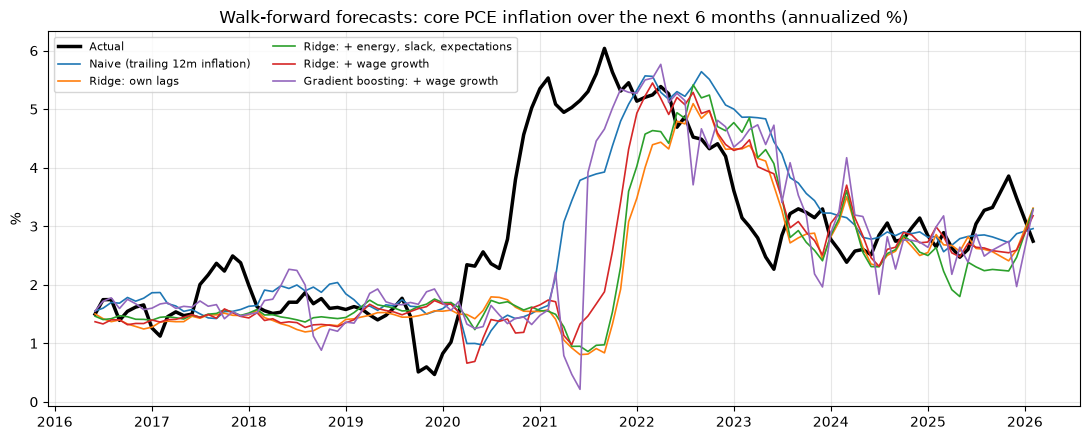

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(preds.index, preds["actual"], color="black", lw=2.5, label="Actual")
for col in preds.columns.drop("actual"):
    ax.plot(preds.index, preds[col], lw=1.2, label=col)
ax.set_title(f"Walk-forward forecasts: core PCE inflation over the next {HORIZON} months (annualized %)")
ax.set_ylabel("%"); ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Conclusions

_Write 3 to 4 sentences after running the notebook, based only on the tables and chart above: whether wage growth adds predictive information, whether the models beat the naive benchmark (and whether the Diebold-Mariano test says the difference is real), and one caveat about sample size or the 2021-22 inflation surge._

## Limitations

- About 15 years of monthly data and overlapping forecast windows mean few independent observations.
- The 2020-22 period is unusual and dominates error metrics, so results are also shown from 2023 onward.
- Granger tests and regressions show predictive relationships, not causal effects.
- Average hourly earnings are affected by composition changes (for example in spring 2020).
- October 2025 is missing from the CPI and household-survey series because of the federal shutdown.